# UPI Fraud Detection - Easy Version
**Goal:** find fraud among UPI payments, and decide for each payment: **Approve**, ask for **OTP**, or **Block**.

### The big idea in simple words
- Fraud is very rare (about 2 in 1000 payments).
- So a "lazy" model that says *"everything is safe"* is **99.8% accurate** but catches **0 frauds**. This is the **accuracy trap**.
- We therefore measure **Recall** (how many frauds we catch) and **Precision** (how many of our alerts are real), and we count **money (₹)**.

### Steps in this notebook
| Step | What we do |
|---|---|
| 1 | Setup |
| 2 | Load and check the data (PS1) |
| 3 | Show the accuracy trap (PS2) |
| 4 | Look for fraud patterns (PS3) |
| 5 | Prepare data and split it |
| 6 | Train models (PS4) |
| 7 | Find "strange" payments without labels (PS5) |
| 8 | Choose the best threshold using money (PS6) |
| 9 | Build the Approve / OTP / Block rule (PS7) |
| 10 | Final test, explanation and recommendations (PS8) |

**How to run:** click `Kernel > Restart & Run All`, or run cell by cell with `Shift + Enter`.

## Step 1 - Setup

In [1]:
# Run this only if a library is missing (remove the # first)
# !pip install pandas numpy scikit-learn xgboost imbalanced-learn matplotlib seaborn scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, precision_recall_curve)
from imblearn.pipeline import Pipeline        # lets us use SMOTE safely (only on training data)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)

### Settings you can change
The organiser has not given the official money values yet. These numbers are **placeholders** - replace them later and re-run.

In [3]:
SEED = 42                       # makes results repeatable
FILE = "upi_transactions_2024.csv"
# If the file is not in the same folder as this notebook, put its full path above.

COST_MISSED_FRAUD = 5000        # ₹X: loss when we MISS one fraud
COST_FALSE_BLOCK  = 500         # ₹Y: loss when we BLOCK one genuine payment
COST_OTP          = 5           # ₹Z: cost of sending one OTP
OTP_STOPS_FRAUD   = 0.80        # assumption: 80% of frauds are stopped by an OTP

## Step 2 - Load and check the data (PS1)
We check: missing values, duplicates, strange amounts, wrong dates and **leakage** (columns that reveal the answer).

In [9]:
import os

df = pd.read_csv("upi_transactions 2024.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (250000, 17)


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [10]:
# Quick health check
print("Missing values   :", df.isna().sum().sum())
print("Duplicate rows   :", df.duplicated().sum())
print("Smallest amount  :", df["amount (INR)"].min(), "| Largest amount:", df["amount (INR)"].max())
print("Amounts <= 0     :", (df["amount (INR)"] <= 0).sum())

Missing values   : 0
Duplicate rows   : 0
Smallest amount  : 10 | Largest amount: 42099
Amounts <= 0     : 0


In [11]:
# Dates: convert text to real dates and check they match hour_of_day
df["timestamp"] = pd.to_datetime(df["timestamp"])
print("Bad dates              :", df["timestamp"].isna().sum())
print("Hour column mismatches :", (df["timestamp"].dt.hour != df["hour_of_day"]).sum())
print("Date range             :", df["timestamp"].min().date(), "to", df["timestamp"].max().date())

Bad dates              : 0
Hour column mismatches : 0
Date range             : 2024-01-01 to 2024-12-30


In [12]:
# Tidy column names and sort by time
df = df.rename(columns={"transaction type": "transaction_type", "amount (INR)": "amount"})
df = df.sort_values("timestamp").reset_index(drop=True)

### Leakage check - which columns must NOT be used?
| Column | Decision | Why |
|---|---|---|
| `transaction id` | Remove | Just an ID number |
| `timestamp` | Remove | We keep `hour_of_day` and `is_weekend` instead |
| `transaction_status` (SUCCESS / FAILED) | **Remove** | Known only *after* the payment is processed |
| `fraud_flag` | This is our **target** | What we want to predict |

There are no balance columns in this data, so there is nothing else to remove.

**Data quality result:** the data is clean (no missing values, no duplicates, no bad amounts, no bad dates).

## Step 3 - The accuracy trap (PS2)
**Target:** `fraud_flag` (1 = fraud, 0 = genuine).

In [13]:
fraud_count = df["fraud_flag"].sum()
fraud_rate = df["fraud_flag"].mean() * 100
print(f"Genuine payments : {len(df) - fraud_count:,}")
print(f"Fraud payments   : {fraud_count:,}")
print(f"Fraud rate       : {fraud_rate:.3f}%")

Genuine payments : 249,520
Fraud payments   : 480
Fraud rate       : 0.192%


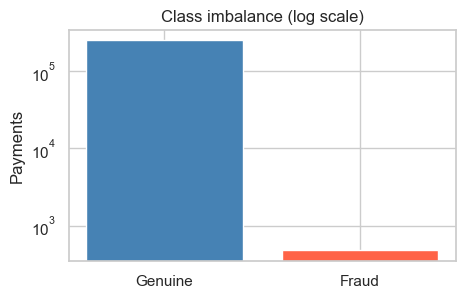

In [14]:
# Chart: how imbalanced is the data? (log scale so the small bar is visible)
counts = df["fraud_flag"].value_counts().sort_index()
plt.figure(figsize=(5, 3))
plt.bar(["Genuine", "Fraud"], counts.values, color=["steelblue", "tomato"])
plt.yscale("log"); plt.title("Class imbalance (log scale)"); plt.ylabel("Payments")
plt.show()

### The lazy model: say 'genuine' for every payment

In [15]:
y = df["fraud_flag"]
lazy_prediction = np.zeros(len(y))        # predicts 0 (genuine) for everyone

print(f"Accuracy : {accuracy_score(y, lazy_prediction)*100:.2f}%   <- looks great")
print(f"Recall   : {recall_score(y, lazy_prediction)*100:.0f}%      <- catches NO fraud at all")
print(f"Money lost: {fraud_count} x ₹{COST_MISSED_FRAUD:,} = ₹{fraud_count*COST_MISSED_FRAUD:,}")

Accuracy : 99.81%   <- looks great
Recall   : 0%      <- catches NO fraud at all
Money lost: 480 x ₹5,000 = ₹2,400,000


**Why this happens:** 99.8% of payments are genuine, so "always genuine" is almost always right - yet it is useless.

**Metrics we will use instead**
- **Recall** = frauds caught / all frauds
- **Precision** = real frauds / all alerts
- **F1** = balance of precision and recall
- **PR-AUC** = the main score for rare events. A random model scores about the fraud rate (~0.002), so we want clearly higher.
- **Expected cost (₹)** = missed frauds x ₹X + wrongly blocked x ₹Y + OTPs x ₹Z

## Step 4 - Fraud patterns (PS3)
We look at *where* fraud happens. These are **patterns, not causes**.

In [16]:
def show_rate(column, title):
    # fraud rate (%) for each group in the column
    rate = df.groupby(column, observed=True)["fraud_flag"].mean() * 100
    rate.plot(kind="bar", figsize=(8, 3), color="tomato")
    plt.axhline(fraud_rate, color="black", linestyle="--", label="Overall average")
    plt.ylabel("Fraud rate (%)"); plt.title(title); plt.legend(); plt.show()
    return rate

**Pattern 1 - Transaction type**

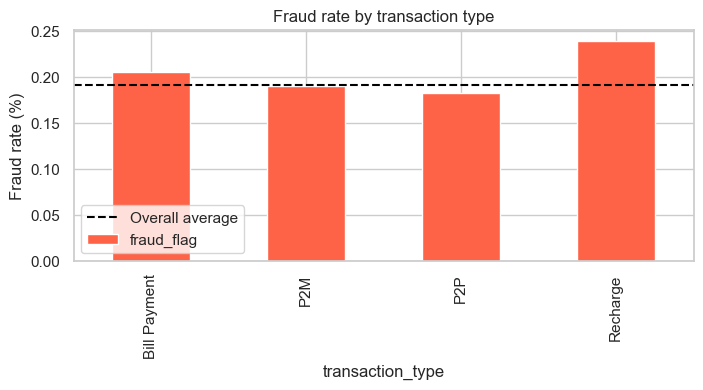

transaction_type
Bill Payment   0.2061
P2M            0.1905
P2P            0.1832
Recharge       0.2395
Name: fraud_flag, dtype: float64

In [17]:
show_rate("transaction_type", "Fraud rate by transaction type")

**Pattern 2 - Amount size**

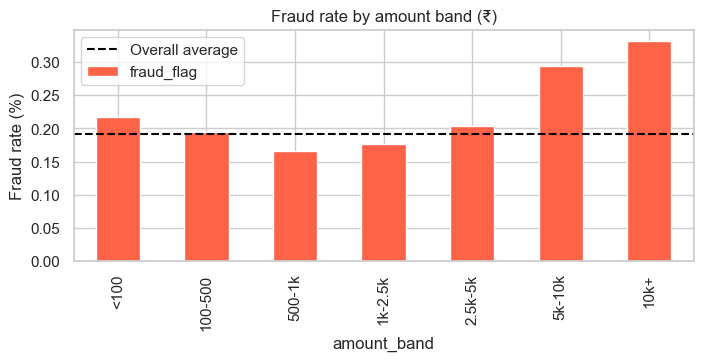

amount_band
<100      0.2174
100-500   0.1951
500-1k    0.1665
1k-2.5k   0.1768
2.5k-5k   0.2043
5k-10k    0.2950
10k+      0.3324
Name: fraud_flag, dtype: float64

In [18]:
bands = [0, 100, 500, 1000, 2500, 5000, 10000, 1e9]
names = ["<100", "100-500", "500-1k", "1k-2.5k", "2.5k-5k", "5k-10k", "10k+"]
df["amount_band"] = pd.cut(df["amount"], bins=bands, labels=names)
show_rate("amount_band", "Fraud rate by amount band (₹)")

In [19]:
# Are fraud amounts bigger than genuine amounts?
df.groupby("fraud_flag")["amount"].describe()[["count", "mean", "50%", "max"]]

,count,mean,50%,max
fraud_flag,,,,
0,"249,520.0000","1,311.3954",629.0000,"42,099.0000"
1,480.0000,"1,499.2313",618.5000,"17,718.0000"


**Pattern 3 - Time of day**

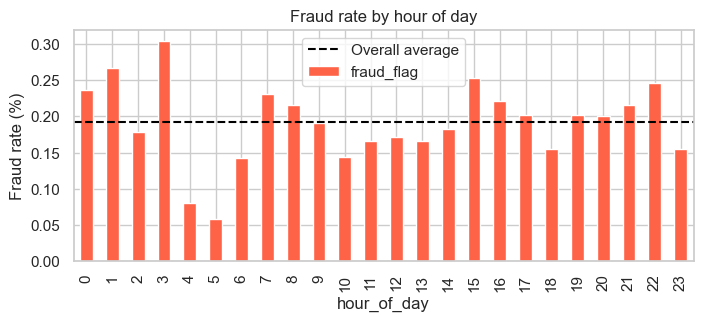

hour_of_day
0    0.2361
1    0.2674
2    0.1780
3    0.3044
4    0.0802
5    0.0574
6    0.1428
7    0.2309
8    0.2156
9    0.1914
10   0.1438
11   0.1654
12   0.1713
13   0.1662
14   0.1831
15   0.2535
16   0.2216
17   0.2017
18   0.1545
19   0.2025
20   0.1999
21   0.2153
22   0.2456
23   0.1547
Name: fraud_flag, dtype: float64

In [20]:
show_rate("hour_of_day", "Fraud rate by hour of day")

### Are these differences real, or just luck?
With only ~480 frauds, small differences can appear by chance. The **chi-square test** checks this.
If **p-value < 0.05** the difference is probably real (still **not** proof of cause).

In [21]:
columns_to_test = ["transaction_type", "amount_band", "hour_of_day", "merchant_category",
                   "device_type", "network_type", "sender_age_group", "sender_state", "sender_bank"]
p_values = {}
for c in columns_to_test:
    p_values[c] = chi2_contingency(pd.crosstab(df[c], df["fraud_flag"]))[1]

pd.Series(p_values, name="p_value").sort_values().to_frame()

,p_value
sender_age_group,0.0255
amount_band,0.1236
sender_bank,0.2384
network_type,0.4353
transaction_type,0.5080
sender_state,0.5580
device_type,0.7959
hour_of_day,0.8597
merchant_category,0.9132


**How to read it:** if most p-values are above 0.05, fraud is spread almost evenly - no single column is a strong warning sign.
This is an honest finding to put in your report.

## Step 5 - Prepare the data and split it
**Features** = the information a model is allowed to use. Text columns are turned into 0/1 columns (`get_dummies`).

**Split by time** (like real life: learn from the past, predict the future):
| Part | Size | Use |
|---|---|---|
| Train | first 60% | teach the models |
| Validation | next 20% | "practice exam": compare models, choose thresholds |
| Test | last 20% | "final exam": used only once at the end |

We split **before** SMOTE, so no information leaks from test to train.

In [22]:
df["is_night"] = df["hour_of_day"].isin([0, 1, 2, 3, 4, 5]).astype(int)
df["same_bank"] = (df["sender_bank"] == df["receiver_bank"]).astype(int)

text_columns = ["transaction_type", "merchant_category", "sender_age_group", "receiver_age_group",
                "sender_state", "sender_bank", "receiver_bank", "device_type", "network_type"]
number_columns = ["amount", "hour_of_day", "is_weekend", "is_night", "same_bank"]

X = pd.concat([df[number_columns], pd.get_dummies(df[text_columns], drop_first=True).astype(int)], axis=1)
y = df["fraud_flag"]
print("Number of features:", X.shape[1])

Number of features: 53


In [23]:
n = len(df)
a, b = int(n * 0.6), int(n * 0.8)          # df is already sorted by time

X_train, y_train = X.iloc[:a],  y.iloc[:a]
X_val,   y_val   = X.iloc[a:b], y.iloc[a:b]
X_test,  y_test  = X.iloc[b:],  y.iloc[b:]

pd.DataFrame({"payments": [len(y_train), len(y_val), len(y_test)],
              "frauds":   [y_train.sum(), y_val.sum(), y_test.sum()]},
             index=["Train", "Validation", "Test"])

,payments,frauds
Train,150000,288
Validation,50000,96
Test,50000,96


## Step 6 - Train supervised models (PS4)
We try **3 models** x **3 ways of handling imbalance**:

| Imbalance method | Meaning |
|---|---|
| `None` | do nothing |
| `Class weights` | tell the model: "a missed fraud is much worse than a false alarm" |
| `SMOTE` | create extra synthetic fraud examples (**only inside training**) |

### A small helper to score a model

In [24]:
def top1_recall(y_true, score):
    # Of all frauds, how many are in the 1% highest-scored payments?
    k = int(len(y_true) * 0.01)
    top = np.argsort(-np.asarray(score))[:k]
    return np.asarray(y_true)[top].sum() / np.sum(y_true)

def score_model(y_true, score, threshold=0.5):
    pred = (score >= threshold).astype(int)
    return {"PR-AUC": average_precision_score(y_true, score),
            "ROC-AUC": roc_auc_score(y_true, score),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred, zero_division=0),
            "Top-1% recall": top1_recall(y_true, score)}

### First, a simple rule baseline (no machine learning)

In [25]:
big_amount = X_train["amount"].quantile(0.99)
rule_pred = ((X_val["amount"] >= big_amount) | (X_val["hour_of_day"] <= 3)).astype(int)

print(f"Rule: flag if amount >= ₹{big_amount:,.0f} OR hour is 0-3  (flags {rule_pred.mean()*100:.1f}% of payments)")
rule_result = score_model(y_val, rule_pred)
pd.DataFrame([rule_result], index=["Rule baseline"])[["Precision", "Recall", "F1", "PR-AUC"]]

Rule: flag if amount >= ₹8,932 OR hour is 0-3  (flags 4.4% of payments)


,Precision,Recall,F1,PR-AUC
Rule baseline,0.0036,0.0833,0.0070,0.0021


### Build the models

In [26]:
ratio = int((y_train == 0).sum() / (y_train == 1).sum())     # genuine : fraud ratio in training data

def make_model(name, method):
    weighted = (method == "Class weights")
    if name == "Logistic Regression":
        clf = LogisticRegression(max_iter=1000, class_weight="balanced" if weighted else None)
    elif name == "Random Forest":
        clf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1,
                                     class_weight="balanced_subsample" if weighted else None, random_state=SEED)
    else:
        clf = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, n_jobs=-1, random_state=SEED,
                            scale_pos_weight=ratio if weighted else 1)
    steps = [("scale", StandardScaler())]
    if method == "SMOTE":
        steps.append(("smote", SMOTE(sampling_strategy=0.1, random_state=SEED)))   # only runs on training data
    steps.append(("model", clf))
    return Pipeline(steps)

### Train all 9 combinations (this can take a few minutes)

In [27]:
model_names = ["Logistic Regression", "Random Forest", "XGBoost"]
methods = ["None", "Class weights", "SMOTE"]

trained, val_scores, rows = {}, {}, []
for name in model_names:
    for method in methods:
        model = make_model(name, method).fit(X_train, y_train)      # learn from TRAIN only
        s = model.predict_proba(X_val)[:, 1]                         # fraud probability on VALIDATION
        trained[(name, method)] = model
        val_scores[(name, method)] = s
        rows.append({"Model": name, "Imbalance method": method, **score_model(y_val, s)})
        print("done:", name, "-", method)

done: Logistic Regression - None
done: Logistic Regression - Class weights


c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File

done: Logistic Regression - SMOTE
done: Random Forest - None
done: Random Forest - Class weights
done: Random Forest - SMOTE
done: XGBoost - None
done: XGBoost - Class weights
done: XGBoost - SMOTE


### Model comparison (validation set)

In [28]:
results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
results

,Model,Imbalance method,PR-AUC,ROC-AUC,Precision,Recall,F1,Top-1% recall
0,Logistic Regression,None,0.0028,0.4695,0.0000,0.0000,0.0000,0.0312
1,Random Forest,None,0.0028,0.5082,0.0000,0.0000,0.0000,0.0208
2,Random Forest,SMOTE,0.0026,0.5552,0.0000,0.0000,0.0000,0.0104
3,Logistic Regression,Class weights,0.0023,0.4763,0.0017,0.3854,0.0035,0.0312
4,Random Forest,Class weights,0.0022,0.5116,0.0000,0.0000,0.0000,0.0104
5,XGBoost,None,0.0020,0.4795,0.0000,0.0000,0.0000,0.0104
6,Logistic Regression,SMOTE,0.0019,0.4948,0.0000,0.0000,0.0000,0.0104
7,XGBoost,SMOTE,0.0019,0.5083,0.0000,0.0000,0.0000,0.0000
8,XGBoost,Class weights,0.0017,0.4653,0.0012,0.0729,0.0024,0.0000


**How to read the table**
- Compare **PR-AUC** with the random level (about **0.002**). If it is only slightly higher, the model has little skill.
- Precision / Recall / F1 here use the default 0.5 cut-off. In Step 8 we replace 0.5 with a smarter, money-based cut-off.
- `Top-1% recall` = share of all frauds found in the top 1% riskiest payments. Random guessing gives about 0.01.

### Weights vs SMOTE (PR-AUC side by side)

In [29]:
results.pivot(index="Model", columns="Imbalance method", values="PR-AUC")[methods]

Imbalance method,None,Class weights,SMOTE
Model,,,
Logistic Regression,0.0028,0.0023,0.0019
Random Forest,0.0028,0.0022,0.0026
XGBoost,0.0020,0.0017,0.0019


### Accuracy vs Recall - the trap, shown with real models

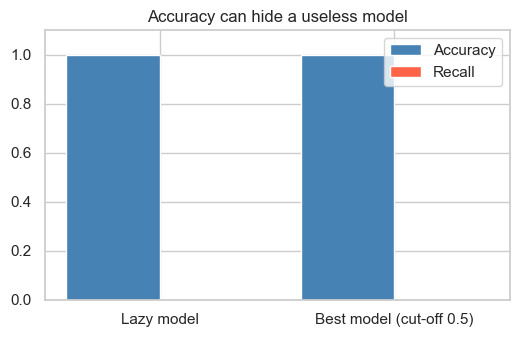

In [30]:
best = results.iloc[0]
best_scores = val_scores[(best["Model"], best["Imbalance method"])]
best_pred = (best_scores >= 0.5).astype(int)

labels = ["Lazy model", "Best model (cut-off 0.5)"]
accuracy = [accuracy_score(y_val, np.zeros(len(y_val))), accuracy_score(y_val, best_pred)]
recall = [0, recall_score(y_val, best_pred)]

x = np.arange(2)
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.2, accuracy, 0.4, label="Accuracy", color="steelblue")
plt.bar(x + 0.2, recall, 0.4, label="Recall", color="tomato")
plt.xticks(x, labels); plt.ylim(0, 1.1); plt.legend(); plt.title("Accuracy can hide a useless model")
plt.show()

## Step 7 - Find strange payments without labels (PS5)
New kinds of fraud have no labels at first. **Isolation Forest** finds payments that look *unusual*.
It is trained **without** `fraud_flag`. We only use the labels **afterwards** to check how well it did.

In [31]:
scaler = StandardScaler().fit(X_train)

iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1)
iso.fit(scaler.transform(X_train))                       # NO fraud labels used here

anomaly_val = -iso.score_samples(scaler.transform(X_val))   # higher = more unusual
print("Isolation Forest trained without labels")

Isolation Forest trained without labels


In [32]:
# Now check against the labels
compare = pd.DataFrame({
    "Isolation Forest (no labels)": [average_precision_score(y_val, anomaly_val), top1_recall(y_val, anomaly_val)],
    "Best supervised model":        [best["PR-AUC"], top1_recall(y_val, best_scores)],
    "Random guess":                 [y_val.mean(), 0.01],
}, index=["PR-AUC", "Frauds found in top 1%"]).T
compare

,PR-AUC,Frauds found in top 1%
Isolation Forest (no labels),0.0021,0.0104
Best supervised model,0.0028,0.0312
Random guess,0.0019,0.0100


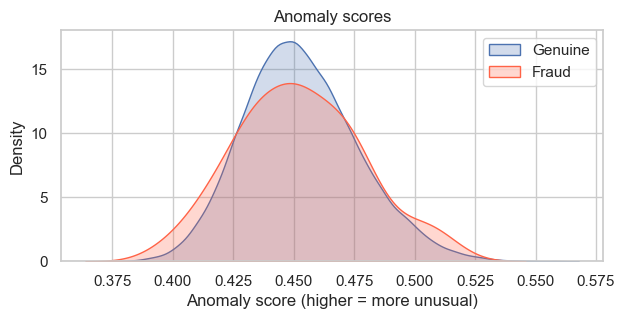

In [33]:
# Do fraud payments look more unusual than genuine ones?
plt.figure(figsize=(7, 3))
sns.kdeplot(anomaly_val[y_val == 0], label="Genuine", fill=True)
sns.kdeplot(anomaly_val[y_val == 1], label="Fraud", fill=True, color="tomato")
plt.xlabel("Anomaly score (higher = more unusual)"); plt.legend(); plt.title("Anomaly scores")
plt.show()

**How to read it:** if the red (fraud) curve sits on top of the blue (genuine) curve, fraud does *not* look unusual in these columns,
so an unlabelled detector cannot find it. Report this honestly.

## Step 8 - Choose the best threshold using money (PS6)
### Precision-Recall curves

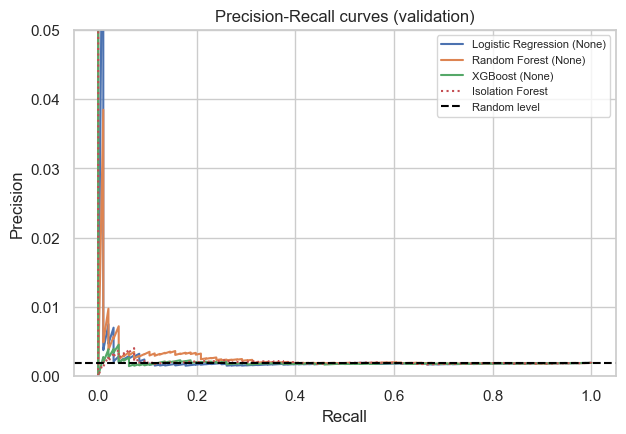

In [34]:
plt.figure(figsize=(7, 4.5))
for name in model_names:
    sub = results[results["Model"] == name].iloc[0]                  # best method for this model
    p, r, _ = precision_recall_curve(y_val, val_scores[(name, sub["Imbalance method"])])
    plt.plot(r, p, label=f"{name} ({sub['Imbalance method']})")
p, r, _ = precision_recall_curve(y_val, anomaly_val)
plt.plot(r, p, ":", label="Isolation Forest")
plt.axhline(y_val.mean(), color="black", linestyle="--", label="Random level")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.ylim(0, 0.05); plt.legend(fontsize=8)
plt.title("Precision-Recall curves (validation)"); plt.show()

### Pick the final model
**Rule we follow:** highest PR-AUC on the validation set (tie-break: top-1% recall).

In [35]:
FINAL = (best["Model"], best["Imbalance method"])
final_model = trained[FINAL]
final_val_scores = val_scores[FINAL]
print("Final model:", FINAL)

Final model: ('Logistic Regression', 'None')


### Expected cost for every threshold
For each threshold we count missed frauds and false blocks, then convert to ₹. We pick the cheapest threshold.

In [36]:
def total_cost(y_true, score, threshold, cost_missed=COST_MISSED_FRAUD, cost_block=COST_FALSE_BLOCK):
    flagged = score >= threshold
    missed = ((~flagged) & (y_true == 1)).sum()
    false_blocks = (flagged & (y_true == 0)).sum()
    return missed * cost_missed + false_blocks * cost_block

y_v = y_val.values
thresholds = np.unique(np.quantile(final_val_scores, np.linspace(0, 1, 500)))   # 500 candidate cut-offs
costs = np.array([total_cost(y_v, final_val_scores, t) for t in thresholds])

BEST_THRESHOLD = thresholds[costs.argmin()]
print(f"Cheapest threshold: {BEST_THRESHOLD:.4f}  | cost: ₹{costs.min():,.0f}")

Cheapest threshold: 0.0161  | cost: ₹480,500


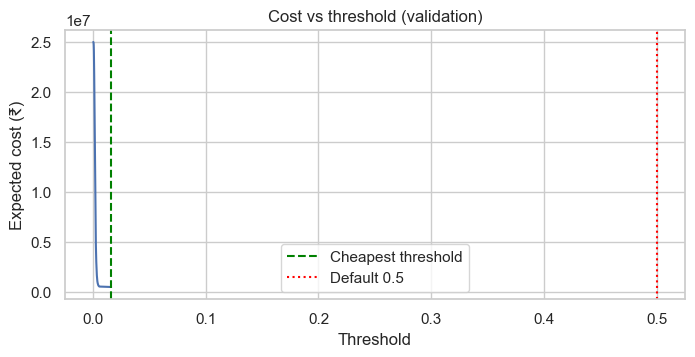

In [37]:
plt.figure(figsize=(8, 3.5))
plt.plot(thresholds, costs)
plt.axvline(BEST_THRESHOLD, color="green", linestyle="--", label="Cheapest threshold")
plt.axvline(0.5, color="red", linestyle=":", label="Default 0.5")
plt.xlabel("Threshold"); plt.ylabel("Expected cost (₹)"); plt.legend(); plt.title("Cost vs threshold (validation)")
plt.show()

### Default 0.5 vs cost-based threshold

In [38]:
approve_all = final_val_scores.max() + 1                       # a threshold so high that nothing is flagged
table = pd.DataFrame({
    "Approve everything": [total_cost(y_v, final_val_scores, approve_all)],
    "Default 0.5":        [total_cost(y_v, final_val_scores, 0.5)],
    "Cost-based":         [total_cost(y_v, final_val_scores, BEST_THRESHOLD)],
}, index=["Cost (₹)"]).T
table["Saving vs 0.5 (₹)"] = table.loc["Default 0.5", "Cost (₹)"] - table["Cost (₹)"]
table

,Cost (₹),Saving vs 0.5 (₹)
Approve everything,480000,0
Default 0.5,480000,0
Cost-based,480500,-500


### What if the costs change?

In [39]:
rows = []
for missed, block in [(1000, 500), (5000, 500), (10000, 500), (20000, 200), (50000, 100)]:
    c = np.array([total_cost(y_v, final_val_scores, t, missed, block) for t in thresholds])
    t_best = thresholds[c.argmin()]
    rows.append({"Missed fraud ₹X": missed, "False block ₹Y": block, "Best threshold": t_best,
                 "% payments flagged": (final_val_scores >= t_best).mean() * 100, "Min cost (₹)": c.min()})
pd.DataFrame(rows)

,Missed fraud ₹X,False block ₹Y,Best threshold,% payments flagged,Min cost (₹)
0,1000,500,0.0161,0.0020,96500
1,5000,500,0.0161,0.0020,480500
2,10000,500,0.0161,0.0020,960500
3,20000,200,0.0058,0.2020,1920000
4,50000,100,0.0035,5.0100,4649700


**How to read it:** when a missed fraud becomes much more expensive than a false block, the best threshold goes **down**
and more payments get flagged. These are **scenario estimates**, not real savings.

## Step 9 - Approve / OTP / Block rule (PS7)
We use **two thresholds** on the risk score:

| Risk score | Decision |
|---|---|
| below `t_otp` | **Approve** |
| between `t_otp` and `t_block` | **Ask for OTP** |
| above `t_block` | **Block** |

To protect customers we limit friction: at most **5%** get an OTP and at most **0.5%** are blocked.

In [40]:
MAX_OTP_SHARE, MAX_BLOCK_SHARE = 0.05, 0.005

def rule_cost(y_true, score, t_otp, t_block):
    approve = score < t_otp
    block = score >= t_block
    otp = ~approve & ~block
    return ((approve & (y_true == 1)).sum() * COST_MISSED_FRAUD                      # frauds we approved
            + otp.sum() * COST_OTP                                                    # OTP messages
            + (otp & (y_true == 1)).sum() * (1 - OTP_STOPS_FRAUD) * COST_MISSED_FRAUD # frauds that beat the OTP
            + (block & (y_true == 0)).sum() * COST_FALSE_BLOCK)                       # genuine customers blocked

In [41]:
# Try many pairs of thresholds and keep the cheapest pair that respects the friction limits
levels = np.unique(np.r_[np.linspace(0.50, 0.99, 50), np.linspace(0.99, 0.9999, 30)])
candidates = np.unique(np.quantile(final_val_scores, levels))

best_rule = None
for i, t_otp in enumerate(candidates):
    for t_block in candidates[i + 1:]:
        otp_share = ((final_val_scores >= t_otp) & (final_val_scores < t_block)).mean()
        block_share = (final_val_scores >= t_block).mean()
        if otp_share > MAX_OTP_SHARE or block_share > MAX_BLOCK_SHARE:
            continue
        c = rule_cost(y_v, final_val_scores, t_otp, t_block)
        if best_rule is None or c < best_rule[0]:
            best_rule = (c, t_otp, t_block)

COST_RULE, T_OTP, T_BLOCK = best_rule
print(f"OTP threshold: {T_OTP:.4f} | Block threshold: {T_BLOCK:.4f} | Cost: ₹{COST_RULE:,.0f}")

OTP threshold: 0.0035 | Block threshold: 0.0113 | Cost: ₹462,975


In [42]:
def band_table(y_true, score):
    band = np.where(score >= T_BLOCK, "Block", np.where(score >= T_OTP, "OTP", "Approve"))
    out = []
    for name in ["Approve", "OTP", "Block"]:
        m = band == name
        out.append({"Band": name, "Payments": m.sum(), "Share %": m.mean() * 100,
                    "Frauds inside": int(y_true[m].sum()), "Genuine inside": int((y_true[m] == 0).sum())})
    return pd.DataFrame(out)

print("Validation set:")
band_table(y_v, final_val_scores)

Validation set:


,Band,Payments,Share %,Frauds inside,Genuine inside
0,Approve,47500,95.0000,88,47412
1,OTP,2495,4.9900,8,2487
2,Block,5,0.0100,0,5


## Step 10 - Final test, explanation and recommendations (PS8)
### 10.1 Final exam on the untouched TEST set
Thresholds were chosen on validation. The test set is used here for the first time.

In [43]:
final_test_scores = final_model.predict_proba(X_test)[:, 1]
y_t = y_test.values

test_result = score_model(y_t, final_test_scores, BEST_THRESHOLD)
print("Final model on TEST (cost-based threshold):")
pd.DataFrame([test_result], index=[f"{FINAL[0]} + {FINAL[1]}"])

Final model on TEST (cost-based threshold):


,PR-AUC,ROC-AUC,Precision,Recall,F1,Top-1% recall
Logistic Regression + None,0.0022,0.5369,0.0000,0.0000,0.0000,0.0000


In [44]:
# Cost on the test set (scenario estimates)
test_costs = pd.DataFrame({
    "Approve everything": [total_cost(y_t, final_test_scores, final_test_scores.max() + 1)],
    "Default 0.5":        [total_cost(y_t, final_test_scores, 0.5)],
    "Cost-based":         [total_cost(y_t, final_test_scores, BEST_THRESHOLD)],
}, index=["Cost (₹)"]).T
test_costs

,Cost (₹)
Approve everything,480000
Default 0.5,480000
Cost-based,482000


### 10.2 Risk rule on the TEST set

In [45]:
print("Test set:")
display(band_table(y_t, final_test_scores))

rule_on_test = rule_cost(y_t, final_test_scores, T_OTP, T_BLOCK)
do_nothing = y_t.sum() * COST_MISSED_FRAUD
print(f"Rule cost: ₹{rule_on_test:,.0f}  |  Approve-everything cost: ₹{do_nothing:,.0f}")
print(f"Scenario saving: ₹{do_nothing - rule_on_test:,.0f}   (estimate, not an observed result)")

Test set:


,Band,Payments,Share %,Frauds inside,Genuine inside
0,Approve,47508,95.0160,92,47416
1,OTP,2485,4.9700,4,2481
2,Block,7,0.0140,0,7


Rule cost: ₹479,925  |  Approve-everything cost: ₹480,000
Scenario saving: ₹75   (estimate, not an observed result)


### 10.3 Which columns matter most? (feature importance)

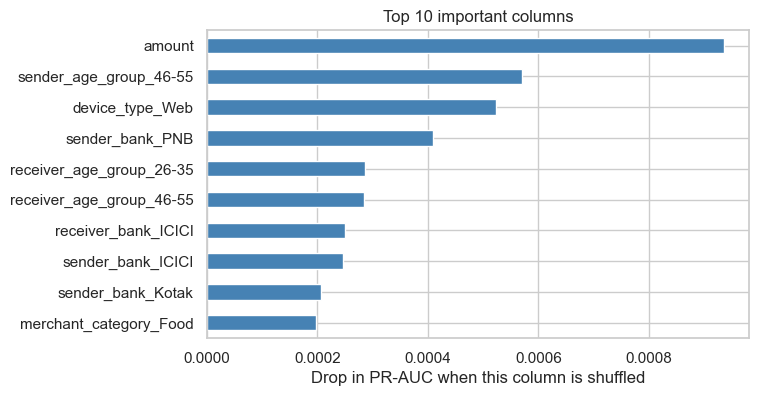

In [46]:
def pr_score(model, X_, y_):
    return average_precision_score(y_, model.predict_proba(X_)[:, 1])

imp = permutation_importance(final_model, X_val, y_val, scoring=pr_score, n_repeats=2, random_state=SEED)
top = pd.Series(imp.importances_mean, index=X_val.columns).sort_values().tail(10)
top.plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.xlabel("Drop in PR-AUC when this column is shuffled"); plt.title("Top 10 important columns"); plt.show()

### 10.4 Numbers to copy into your report

In [47]:
test_pr = average_precision_score(y_t, final_test_scores)
iso_test = -iso.score_samples(scaler.transform(X_test))

print("OBSERVED RESULTS")
print(f"1. Fraud rate {fraud_rate:.3f}%. Lazy model: accuracy {accuracy_score(y, lazy_prediction)*100:.2f}%, recall 0%.")
print("2. Columns with a real difference (p<0.05):", [c for c, p in p_values.items() if p < 0.05] or "none")
print(f"3. Final model test PR-AUC: {test_pr:.4f}  vs random level {y_t.mean():.4f}")
print(f"4. Top-1% recall on test -> model: {top1_recall(y_t, final_test_scores)*100:.1f}%, Isolation Forest: {top1_recall(y_t, iso_test)*100:.1f}%, random: 1%")
print()
print("SCENARIO ESTIMATE (placeholder costs)")
print(f"5. Rule vs approve-everything on test: ₹{do_nothing - rule_on_test:,.0f}")

OBSERVED RESULTS
1. Fraud rate 0.192%. Lazy model: accuracy 99.81%, recall 0%.
2. Columns with a real difference (p<0.05): ['sender_age_group']
3. Final model test PR-AUC: 0.0022  vs random level 0.0019
4. Top-1% recall on test -> model: 0.0%, Isolation Forest: 2.1%, random: 1%

SCENARIO ESTIMATE (placeholder costs)
5. Rule vs approve-everything on test: ₹75


### 10.5 Three findings and three recommendations
Fill these in after you run the notebook, using the numbers in 10.4. Each one is **Finding -> Evidence -> Action**.

**1. Accuracy is misleading**
- *Finding:* the lazy model scores ~99.8% accuracy but catches no fraud.
- *Action (high priority):* report recall, precision, PR-AUC and ₹ cost - never accuracy alone.

**2. How much fraud signal is in the data?**
- *Finding:* write the final PR-AUC vs the random level and the chi-square result.
- *Action (high priority):* if the model is only slightly better than random, collect better information (how many payments the sender made in the last hour, new payee, new device, amount compared with the sender's usual amount, age of the receiver account).

**3. Use money-based thresholds and three bands**
- *Finding:* compare the cost table (Step 8) and band table (Step 10.2).
- *Action (medium priority):* replace the default 0.5 with the cost-based thresholds and the Approve / OTP / Block rule. Review them whenever the real ₹ costs change.

### 10.6 Limitations
- The ₹ costs and the 80% OTP success rate are **placeholders / assumptions**.
- The data looks **simulated**, so results may not match real UPI traffic.
- Only ~480 frauds, so results (about 100 frauds in validation and test) can change a lot by chance.
- There is no customer history (velocity, device change, new payee).
- Patterns are **associations, not causes**.
- Projected savings are **scenario estimates**, not observed results.